# 2. Logistic regression: modelling where a map is wrong

The error of a map at a point is a binary variable, so the Gaussian linear model does not apply. I use
the binomial GLM with a logit link (logistic regression), checked and tested with the same frequentist
approach as in the course: likelihood-ratio tests, backward selection, simulated residuals.

The model is fitted on the **development half** of the points only. The other half is kept untouched
for the final benchmark of notebook 3.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from alval.data import load_points, INDICATORS, PRODUCTS, REGIONS
from alval import plots

pd.set_option("display.precision", 3)
points = load_points()

In [2]:
from alval import glm

dev = points[points["split"] == "dev"].copy()
# standardise the indicators so that odds ratios are read per standard deviation
for c in INDICATORS:
    dev[c] = (dev[c] - dev[c].mean()) / dev[c].std()
dev["region"] = dev["region"].astype("category")
len(dev)

5019

## Full model for WorldCover errors

In [3]:
formula = "err_wc ~ " + " + ".join(INDICATORS) + " + C(region)"
full = glm.fit_logit(formula, dev)
print(full.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 err_wc   No. Observations:                 5019
Model:                            GLM   Df Residuals:                     5009
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2342.2
Date:                Mon, 02 Nov 2026   Deviance:                       4684.4
Time:                        10:34:44   Pearson chi2:                 4.97e+03
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1753
Covariance Type:            nonrobust                                         
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

### Likelihood-ratio test of each term (drop1)

In [4]:
glm.drop1(full, dev).round(4)

,df,deviance_increase,AIC_without,p_value
term,,,,
n_classes,1,181.132,4883.567,0.000e+00
dominant_share,1,33.176,4735.611,0.000e+00
C(region),3,25.701,4724.135,0.000e+00
edge_distance,1,15.508,4717.943,1.000e-04
oso_confidence,1,10.392,4712.827,1.300e-03
dw_entropy,1,8.570,4711.005,3.400e-03
heterogeneity,1,0.062,4702.497,8.031e-01


### Backward selection

Terms are removed one at a time while their likelihood-ratio test is not significant at 5%.

In [5]:
selected = glm.backward_selection(formula, dev)
glm.odds_ratios(selected).round(3)

dropping heterogeneity (p = 0.803)


,odds_ratio,low,high,p_value
C(region)[T.Grand Est],0.949,0.773,1.167,0.621
C(region)[T.Massif Central],0.642,0.506,0.816,0.000
C(region)[T.Occitanie],1.109,0.898,1.369,0.337
n_classes,1.773,1.628,1.930,0.000
dominant_share,0.736,0.677,0.799,0.000
edge_distance,0.788,0.694,0.895,0.000
oso_confidence,0.883,0.819,0.952,0.001
dw_entropy,1.136,1.042,1.239,0.004


## Checking the model: simulated residuals

Raw residuals of a binary model are hard to read. Following the idea of the DHARMa package, each
observation is compared with 1,000 responses simulated from the fitted model; if the model is right,
these residuals are uniform on [0, 1].

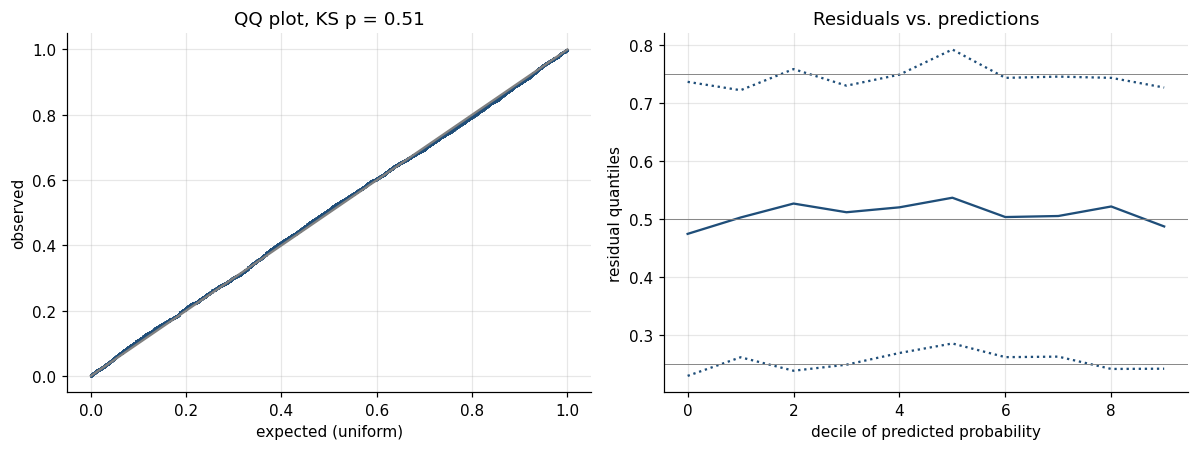

In [6]:
res = glm.simulated_residuals(selected, n_sim=1000)
ks = glm.uniformity_test(res)
fitted = selected.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
q = np.sort(res)
axes[0].plot(np.linspace(0, 1, len(q)), q, ".", ms=2, color="#1f4e79")
axes[0].plot([0, 1], [0, 1], color="grey")
axes[0].set(xlabel="expected (uniform)", ylabel="observed", title=f"QQ plot, KS p = {ks.pvalue:.2f}")
bins = pd.qcut(fitted.rank(), 10, labels=False)
summary = pd.DataFrame({"bin": bins, "r": res}).groupby("bin")["r"].quantile([0.25, 0.5, 0.75]).unstack()
for col, ls in zip(summary.columns, (":", "-", ":")):
    axes[1].plot(summary.index, summary[col], ls, color="#1f4e79")
for h in (0.25, 0.5, 0.75):
    axes[1].axhline(h, color="grey", lw=0.6)
axes[1].set(xlabel="decile of predicted probability", ylabel="residual quantiles",
            title="Residuals vs. predictions")
fig.tight_layout()

## Are the points independent? Spatial checks

The tests above assume independent observations, but LUCAS points sit on a regular grid and
neighbouring points share their landscape. Two checks: standard errors robust to clustering by 20 km
spatial block (the unit used everywhere else in the project), and Moran's I of the residuals between
points less than 5 km apart, with a permutation test.

In [7]:
clustered = glm.fit_logit(selected.model.formula, dev, groups=dev["block_id"])
print(f"{dev['block_id'].nunique()} blocks, median {dev.groupby('block_id').size().median():.0f} points per block")
display(pd.DataFrame({"se_independent": selected.bse, "se_clustered": clustered.bse,
                      "ratio": clustered.bse / selected.bse, "p_clustered": clustered.pvalues}).round(4))

moran = glm.morans_i(selected.resid_response, dev[["x_l93", "y_l93"]].to_numpy(), distance=5000)
print(f"Moran's I of the residuals (5 km): {moran['I']:.4f} (expected {moran['expected']:.4f}), "
      f"permutation p = {moran['p_value']:.2f}, {moran['n_pairs']} pairs")

285 blocks, median 15 points per block


,se_independent,se_clustered,ratio,p_clustered
Intercept,0.086,0.071,0.825,0.000
C(region)[T.Grand Est],0.105,0.089,0.846,0.559
C(region)[T.Massif Central],0.122,0.108,0.884,0.000
C(region)[T.Occitanie],0.107,0.100,0.931,0.302
n_classes,0.043,0.047,1.074,0.000
dominant_share,0.042,0.043,1.007,0.000
edge_distance,0.065,0.076,1.176,0.002
oso_confidence,0.038,0.040,1.044,0.002
dw_entropy,0.044,0.041,0.924,0.002


Moran's I of the residuals (5 km): -0.0104 (expected -0.0002), permutation p = 0.86, 11611 pairs


## From explanation to prediction: does the model transfer between regions?

For sampling, what matters is the ability to rank points by risk of error in a region where no field
data exist yet. I train the model on three regions and evaluate it on the fourth (leave-one-region-out,
development half), for three feature sets:

- the six indicators;
- *enriched*: plus the class stated by the map and its agreement with the other maps;
- *fifth opinion*: plus what an independent classifier, trained on satellite embeddings, says about the
  stated class.

In [8]:
from sklearn.metrics import roc_auc_score
from alval.data import by_region
from alval.features import transferred_errors

dev_regions = by_region(points, split="dev")
rows = []
for region, target in dev_regions.items():
    train = {r: d for r, d in dev_regions.items() if r != region}
    for code in PRODUCTS:
        for feats in ("indicators", "enriched", "opinion"):
            f = transferred_errors(train, target, code, feats)
            rows.append({"region": region, "map": code, "features": feats,
                         "auc": roc_auc_score(target[f"err_{code}"], f)})
auc = pd.DataFrame(rows)
auc.pivot_table(index=["region", "map"], columns="features", values="auc").round(3)

features            enriched  indicators  opinion
region         map                               
Brittany       clc     0.763       0.701    0.782
               dw      0.876       0.818    0.885
               oso     0.805       0.752    0.818
               wc      0.833       0.786    0.846
Grand Est      clc     0.737       0.729    0.766
               dw      0.846       0.819    0.861
               oso     0.781       0.757    0.798
               wc      0.784       0.769    0.806
Massif Central clc     0.774       0.743    0.818
               dw      0.898       0.865    0.918
               oso     0.822       0.789    0.854
               wc      0.795       0.752    0.831
Occitanie      clc     0.752       0.697    0.792
               dw      0.829       0.772    0.851
               oso     0.793       0.736    0.817
               wc      0.775       0.744    0.805

In [9]:
auc.groupby("features")["auc"].describe()[["mean", "50%", "min", "max"]].round(3)

,mean,50%,min,max
features,,,,
enriched,0.804,0.794,0.737,0.898
indicators,0.764,0.755,0.697,0.865
opinion,0.828,0.818,0.766,0.918


## What I take from this

- **Disagreement between products is the strongest signal**: each standard deviation of `n_classes`
  multiplies the odds of a WorldCover error by 1.77 [1.63; 1.93]. Homogeneous surroundings and distance
  to edges lower the risk (odds ratios 0.74 and 0.79), a confident OSO too (0.88).
- **Heterogeneity is dropped** (likelihood-ratio p = 0.80): once the other indicators are in the model it
  adds nothing, consistent with its strong correlation with Dim.1 in the PCA.
- **The region effect remains** (likelihood-ratio test, p < 0.001), mainly a lower risk in the Massif
  Central at equal indicators.
- **The model is adequate**: simulated residuals are uniform (KS p = 0.51) with no trend along the
  predictions.
- **Spatial dependence is weak once the indicators are in the model.** Clustering by block changes the
  standard errors by at most about 18% and every term stays significant; the residuals show no spatial
  autocorrelation at 5 km (Moran's I close to its expected value). The p-values above are therefore not an
  artefact of neighbouring points, although the selection step itself makes the final intervals slightly
  optimistic.
- **It transfers.** Trained in three regions and tested in the fourth, the median AUC is 0.755 with the six
  indicators, 0.794 with the enriched features and 0.818 with the fifth opinion. This transferred model is
  what the active learning engine starts from.